In [166]:
import numpy as np
import torch

%load_ext jupyter_black

The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black


In [167]:
np.array([21, 43]) + 1

array([22, 44])

### learnable things in architecture for https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf

1. the things from the research paper we learn is w, b and C(Lookup table for embedding)
2. C -> lookup table of vectors for each word(17,000) in paper
    and let say embedding dim=30 so c.shape = (17,000, 30)

In [168]:
words = open("names.txt").read().splitlines()
len(words)

32033

In [169]:
chars = sorted(list(set("".join(words))))
ctoi = {s: i + 1 for i, s in enumerate(chars)}
ctoi["."] = 0
itoc = {i: c for c, i in ctoi.items()}
print(itoc)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


### build dataset

In [5]:
# context length of how many characters do we take to predict next one
block_size = 3
X, y = [], []

for w in words[:2]:
    print(w)
    context = [0] * block_size

    for ch in w + ".":
        ix = ctoi[ch]
        X.append(context)
        y.append(ix)
        print("".join(itoc[i] for i in context), "-->", itoc[ix])
        context = context[1:] + [ix]

X = torch.tensor(X)
y = torch.tensor(y)

emma
... --> e
..e --> m
.em --> m
emm --> a
mma --> .
olivia
... --> o
..o --> l
.ol --> i
oli --> v
liv --> i
ivi --> a
via --> .


In [6]:
X[:3], y[:3]

(tensor([[ 0,  0,  0],
         [ 0,  0,  5],
         [ 0,  5, 13]]),
 tensor([ 5, 13, 13]))

In [7]:
# 27 because 26 chars(a-z) + . = 26+1=27
C = torch.randn((27, 2))
C[:4]

tensor([[-0.0054, -1.4511],
        [ 0.3582, -0.6418],
        [-0.8161,  0.7532],
        [-1.9877, -1.1340]])

In [8]:
import torch.nn.functional as F

In [9]:
F.one_hot(torch.tensor(5), num_classes=27)

tensor([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0])

In [10]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([-1.7447,  1.1218])

In [11]:
print(C[X].shape, "\n", C[X][:2])

torch.Size([12, 3, 2]) 
 tensor([[[-0.0054, -1.4511],
         [-0.0054, -1.4511],
         [-0.0054, -1.4511]],

        [[-0.0054, -1.4511],
         [-0.0054, -1.4511],
         [-1.7447,  1.1218]]])


In [12]:
# take 2nd out of 3 array in the 7th datapt in X, understand while looking the second part
X[7, 2], C[X][7, 2]

(tensor(12), tensor([-0.4528, -0.9707]))

In [13]:
C[12]

tensor([-0.4528, -0.9707])

In [14]:
emb = C[X]
emb.shape

torch.Size([12, 3, 2])

In [15]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [16]:
emb @ W1 + b1

RuntimeError: mat1 and mat2 shapes cannot be multiplied (36x2 and 6x100)

In [17]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape

torch.Size([12, 6])

In [18]:
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([12, 6])

In [19]:
emb.view(12, 6) == torch.cat(torch.unbind(emb, 1), 1)

tensor([[True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True]])

In [20]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
h.shape

torch.Size([12, 100])

In [21]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [22]:
logits = h @ W2 + b2
print("Shape of logits = ", logits.shape)
exp = torch.exp(logits)
den = exp.sum(axis=1)
print("den shape = ", den.shape)

prob = exp / den.reshape(-1, 1)  # softmax
print("softmax shape = ", prob.shape)
idxs = prob.argmax(dim=1)
idxs.shape

Shape of logits =  torch.Size([12, 27])
den shape =  torch.Size([12])
softmax shape =  torch.Size([12, 27])


torch.Size([12])

In [23]:
# negative log likelihood
loss = -prob[torch.arange(12), y].log().mean()
loss

tensor(21.4419)

In [24]:
F.cross_entropy(logits, y)

tensor(21.4419)

In [25]:
def demonstrate_cross_entropy():
    temp = torch.tensor([-100, -2, 3, 100])  # problem as e^100
    counts = temp.exp()
    prob = counts / counts.sum()
    print(prob)


demonstrate_cross_entropy()

tensor([0., 0., 0., nan])


### F.cross_entropy calculates the max value and subtracts it to all cause it has no effect on probabliey

In [26]:
def demonstrate_cross_entropy_fixed():
    temp = torch.tensor([-100, -2, 3, 100])
    temp -= temp.max()
    counts = temp.exp()
    prob = counts / counts.sum()
    print(prob)


demonstrate_cross_entropy_fixed()

tensor([0.0000e+00, 5.6052e-45, 7.4689e-43, 1.0000e+00])


### main training

In [27]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]

In [28]:
for p in parameters:
    p.requires_grad = True

sum(p.numel() for p in parameters if p.requires_grad)

3481

In [29]:
for _ in range(100):
    # forward pass
    emb = C[X]  # (f, 3,2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, y)

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    for p in parameters:
        p.data -= 0.1 * p.grad
print(loss.item())

0.1288602203130722


## do clean training

In [30]:
def build_dataset(block_size=3):
    # context length of how many characters do we take to predict next one
    X, y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size

        for ch in w + ".":
            ix = ctoi[ch]
            X.append(context)
            y.append(ix)
            # print("".join(itoc[i] for i in context), "-->", itoc[ix])
            context = context[1:] + [ix]

    X = torch.tensor(X)
    y = torch.tensor(y)
    return X, y

In [31]:
X, y = build_dataset(3)
X.shape, y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [32]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [33]:
for _ in range(20):
    # forward pass
    emb = C[X]  # (f,2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, y)

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    for p in parameters:
        p.data -= 0.1 * p.grad
    print(loss.item())

19.505229949951172
17.084484100341797
15.776532173156738
14.833342552185059
14.002608299255371
13.253264427185059
12.57992172241211
11.983104705810547
11.47049617767334
11.051857948303223
10.70959186553955
10.407635688781738
10.12781047821045
9.864368438720703
9.614505767822266
9.37644100189209
9.148946762084961
8.931113243103027
8.722232818603516
8.521750450134277


In [34]:
def test_model(s: str):
    x = torch.tensor([ord(c) - ord("a") for c in s])
    print(x.shape)
    emb = C[x]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    print(h.shape)
    logits = h @ W2 + b2  # (f,27)
    print(logits.shape)
    counts = logits.exp()
    prob = counts / counts.sum(dim=1, keepdims=True)
    print(prob.shape)
    pidx = prob.argmax(dim=1).item()
    pchar = itoc[pidx]
    return pchar

In [35]:
test_model("mma")

torch.Size([3])
torch.Size([1, 100])
torch.Size([1, 27])
torch.Size([1, 27])


'j'

In [36]:
torch.randint(0, X.shape[0], (32,))

tensor([159813,  47727, 174440,  17897,  71646, 114366,  28645, 117283,  42051,
         48527, 145826, 154764,  98444, 213518,  86422, 178385,  93029, 196813,
        134629,   6635, 167463,  77581,  74743, 130834, 178509, 128434, 219163,
        197300, 112262,  29327, 192811,  77746])

In [37]:
# batch gradient descent
for _ in range(100):
    ix = torch.randint(0, X.shape[0], (32,))
    # forward pass
    emb = C[X[ix]]  # (32,2,3)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, y[ix])

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    for p in parameters:
        p.data -= 0.1 * p.grad
print(loss.item())

3.528101921081543


In [38]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, y)
loss  # full training set

tensor(3.5379, grad_fn=<NllLossBackward0>)

### how to determine the learning rate

In [39]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [40]:
lossi = []
lri = []

for i in range(1000):
    ix = torch.randint(0, X.shape[0], (32,))
    # forward pass
    emb = C[X[ix]]  # (32,2,3)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, y[ix])

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    lr = lrs[i]
    for p in parameters:
        p.data -= lr * p.grad

    lri.append(lr)
    lossi.append(loss.item())

print(loss.item())

8.542853355407715


In [41]:
import matplotlib.pyplot as plt

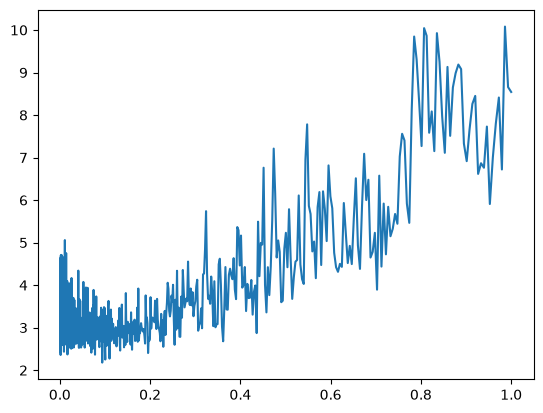

In [42]:
plt.plot(lri, lossi)

In [43]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [44]:
lossi = []
lri = []

for i in range(1000):
    ix = torch.randint(0, X.shape[0], (32,))
    # forward pass
    emb = C[X[ix]]  # (32,2,3)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, y[ix])

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    lr = lrs[i]
    for p in parameters:
        p.data -= lr * p.grad

    lri.append(lre[i])  # just changed here
    lossi.append(loss.item())

print(loss.item())

8.99699592590332


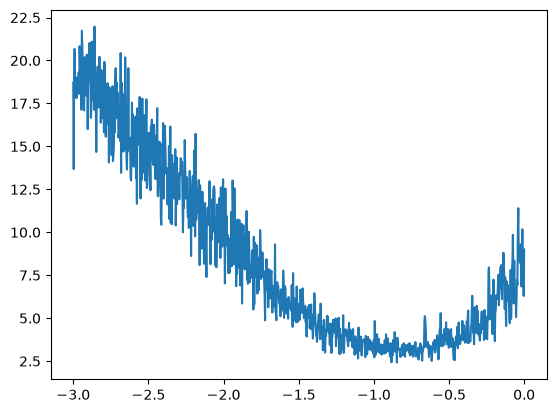

In [45]:
plt.plot(lri, lossi)

In [46]:
# now we can use the info from above and set lr
for i in range(10000):
    ix = torch.randint(0, X.shape[0], (32,))
    # forward pass
    emb = C[X[ix]]  # (32,2,3)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, y[ix])

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    # lr = 0.1
    lr = 0.01  # lr decay
    for p in parameters:
        p.data -= lr * p.grad

print(loss.item())

2.520662307739258


In [47]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, y)
loss  # full training set

tensor(2.5157, grad_fn=<NllLossBackward0>)

### train, val and test split (80, 10, 10)

In [48]:
# build the dataset
block_size = (
    3  # context length: how many characters do we take to predict the next one?
)


def build_dataset(words):
    X, Y = [], []
    for w in words:

        # print(w)
        context = [0] * block_size
        for ch in w + ".":
            ix = ctoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [49]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 300), generator=g)
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

sum(p.nelement() for p in parameters if p.requires_grad)

10281

In [50]:
lossi = []
lri = []
stepi = []

for i in range(30000):
    ix = torch.randint(0, Xtr.shape[0], (32,))
    # forward pass
    emb = C[Xtr[ix]]  # (32,2,3)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    # lr = 0.1
    lr = 0.01  # lr decay
    for p in parameters:
        p.data -= lr * p.grad

    # lri.append(lr)
    stepi.append(i)
    lossi.append(loss.item())

print(loss.item())

2.582672357559204


In [51]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss  # full training set

tensor(2.4857, grad_fn=<NllLossBackward0>)

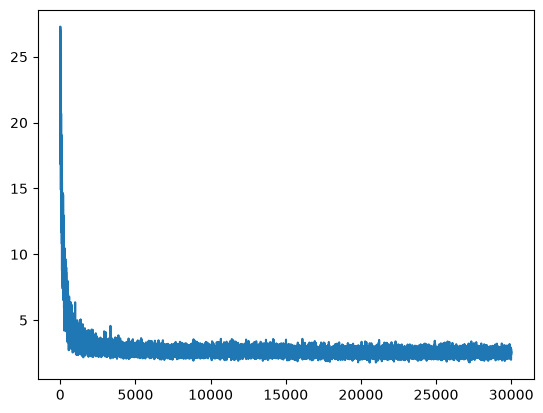

In [52]:
plt.plot(stepi, lossi)

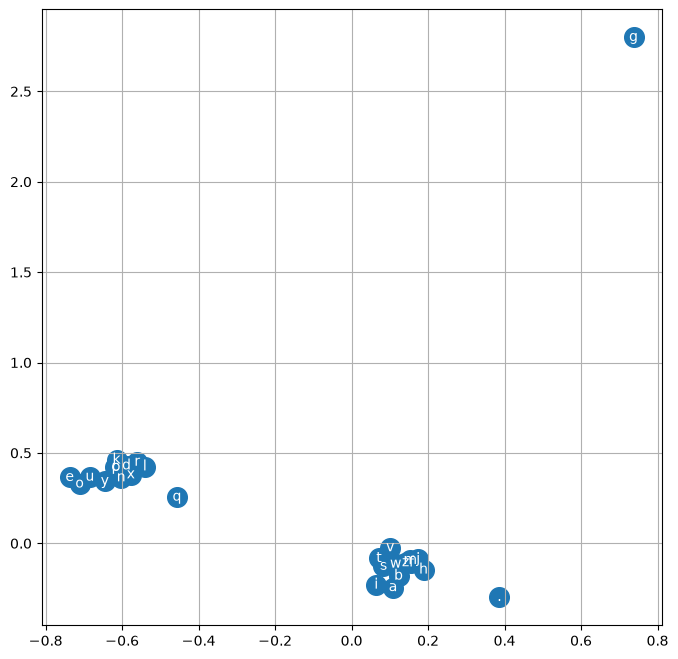

In [53]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(
        C[i, 0].item(), C[i, 1].item(), itoc[i], ha="center", va="center", color="white"
    )
plt.grid("minor")

### grow the embedding dim size

In [64]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

sum(p.nelement() for p in parameters if p.requires_grad)

11897

In [65]:
lossi = []
lri = []
stepi = []

In [66]:
for i in range(200000):
    ix = torch.randint(0, Xtr.shape[0], (32,))
    # forward pass
    emb = C[Xtr[ix]]  # (32,2,3)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    lr = 0.1 if i < 100000 else 0.01
    # lr = 0.01  # lr decay
    for p in parameters:
        p.data -= lr * p.grad

    # lri.append(lr)
    stepi.append(i)
    lossi.append(loss.log10().item())

print(loss.item())

2.4203667640686035


In [67]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss  # full training set

tensor(2.1695, grad_fn=<NllLossBackward0>)

In [68]:
emb = C[Xte]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.1768, grad_fn=<NllLossBackward0>)

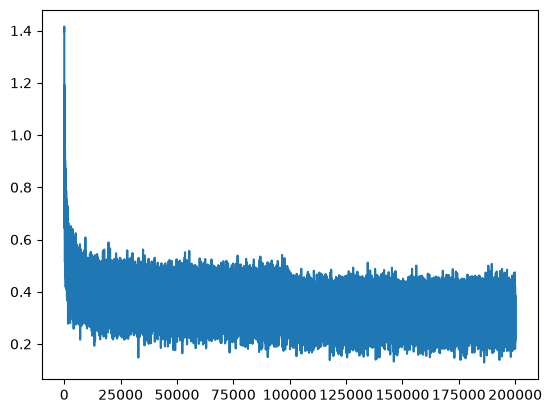

In [69]:
plt.plot(stepi, lossi)

In [70]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [71]:
def predictions(g, names_len=20):
    for _ in range(names_len):
        out = []
        context = [0] * block_size

        while True:
            emb = C[torch.tensor([context])]  # (1,block_size,d)
            h = torch.tanh(emb.view(1, -1) @ W1 + b1)
            logits = h @ W2 + b2
            probs = F.softmax(logits, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:
                break

        print("".join(itoc[i] for i in out))

In [72]:
g = torch.Generator().manual_seed(2147483647 + 10)
predictions(g)

carmahzaan.
hari.
kemri.
ree.
cassanden.
jazhubedemerah.
jareen.
ner.
kentzeriiv.
kaleigh.
ham.
join.
quinn.
sulie.
alvin.
quinaelo.
dearynix.
kael.
dura.
med.


### playinging around

In [73]:
emb = C[Xte]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.1768, grad_fn=<NllLossBackward0>)

### goal to beat the above test loss

In [74]:
import matplotlib.pyplot as plt

In [170]:
block_size = 4  # context length
emb_dim = 16
in_features = emb_dim * block_size


def build_dataset(words):
    X, Y = [], []
    for w in words:

        # print(w)
        context = [0] * block_size
        for ch in w + ".":
            ix = ctoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

random.seed(42)
random.shuffle(words)
n1 = int(0.80 * len(words))
n2 = int(0.90 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 4]) torch.Size([182625])
torch.Size([22655, 4]) torch.Size([22655])
torch.Size([22866, 4]) torch.Size([22866])


In [171]:
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((27, emb_dim), generator=g)
W1 = torch.randn((in_features, 512), generator=g)
b1 = torch.randn(512, generator=g)
W2 = torch.randn((512, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

sum(p.nelement() for p in parameters if p.requires_grad)

47563

In [172]:
for p in parameters:
    print(p.shape)

torch.Size([27, 16])
torch.Size([64, 512])
torch.Size([512])
torch.Size([512, 27])
torch.Size([27])


In [173]:
lossi = []
stepi = []
best_loss = float("inf")
in_features

64

In [175]:
batch_size = (128,)
alpha = 0.01

for i in range(200000):
    ix = torch.randint(0, Xtr.shape[0], batch_size)
    # forward pass
    emb = C[Xtr[ix]]  # (batc_size,2,3)
    h = torch.sigmoid(emb.view(-1, in_features) @ W1 + b1)  # (f, 100)
    logits = h @ W2 + b2  # (f,27)
    # print(logits.shape)
    loss = F.cross_entropy(
        logits, Ytr[ix]
    )  # + (alpha * (W1**2).sum() + (W2**2).sum()) # loss + l2 reg

    # backward pass
    for p in parameters:  # zero grad
        p.grad = None
    loss.backward()

    if i < 100000:
        lr = 0.1
    elif i < 150000:
        lr = 0.01
    else:
        lr = 0.001
    # lr = 0.1 if i < 100000 else 0.01

    for p in parameters:
        p.data -= lr * p.grad

    stepi.append(i)
    lossi.append(loss.log10().item())
    if loss.item() < best_loss:
        best_state_dict = {
            "C": C.clone().detach(),
            "W1": W1.clone().detach(),
            "b1": b1.clone().detach(),
            "W2": W2.clone().detach(),
            "b2": b2.clone().detach(),
        }
        best_loss = loss.item()
    if i % 5000 == 0:
        print(f"Step {i}, Loss: {loss.item():.4f}, LR: {lr:.6f}")

print(loss.item())

Step 0, Loss: 31.1887, LR: 0.100000
Step 5000, Loss: 2.3434, LR: 0.100000
Step 10000, Loss: 2.3071, LR: 0.100000
Step 15000, Loss: 2.3673, LR: 0.100000
Step 20000, Loss: 2.6271, LR: 0.100000
Step 25000, Loss: 2.3127, LR: 0.100000
Step 30000, Loss: 2.5512, LR: 0.100000
Step 35000, Loss: 2.3507, LR: 0.100000
Step 40000, Loss: 2.3613, LR: 0.100000
Step 45000, Loss: 2.1172, LR: 0.100000
Step 50000, Loss: 2.3411, LR: 0.100000
Step 55000, Loss: 2.1301, LR: 0.100000
Step 60000, Loss: 2.1550, LR: 0.100000
Step 65000, Loss: 2.2004, LR: 0.100000
Step 70000, Loss: 2.5550, LR: 0.100000
Step 75000, Loss: 2.3011, LR: 0.100000
Step 80000, Loss: 2.1974, LR: 0.100000
Step 85000, Loss: 2.0116, LR: 0.100000
Step 90000, Loss: 2.2727, LR: 0.100000
Step 95000, Loss: 2.1532, LR: 0.100000
Step 100000, Loss: 2.2345, LR: 0.010000
Step 105000, Loss: 2.1030, LR: 0.010000
Step 110000, Loss: 1.9905, LR: 0.010000
Step 115000, Loss: 2.1187, LR: 0.010000
Step 120000, Loss: 1.8231, LR: 0.010000
Step 125000, Loss: 2.011

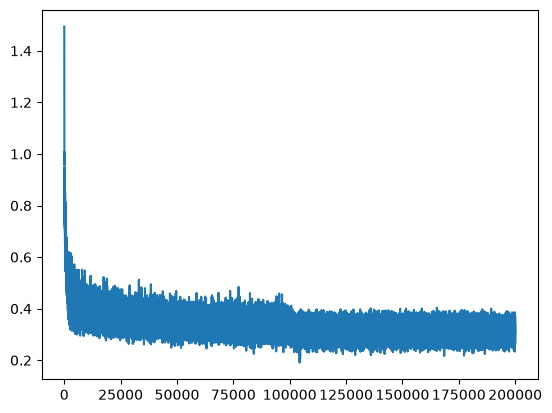

In [176]:
plt.plot(stepi, lossi)

In [177]:
best_C = best_state_dict["C"]
best_W1 = best_state_dict["W1"]
best_b1 = best_state_dict["b1"]
best_W2 = best_state_dict["W2"]
best_b2 = best_state_dict["b2"]

In [178]:
best_loss, (C == best_C).sum()

(1.5520603656768799, tensor(0))

In [181]:
@torch.no_grad()
def evaluate_split(X, Y):
    emb = C[X]
    h = torch.sigmoid(emb.view(-1, in_features) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y)
    return loss.item()


print(f"Final Train Loss: {evaluate_split(Xtr, Ytr):.4f}")
print(f"Final Dev Loss:   {evaluate_split(Xdev, Ydev):.4f}")
print(f"Final Test Loss:   {evaluate_split(Xte, Yte):.4f}")

Final Train Loss: 2.0677
Final Dev Loss:   2.1107
Final Test Loss:   2.1049


In [182]:
@torch.no_grad()
def evaluate_split_best(X, Y):
    emb = best_C[X]
    h = torch.sigmoid(emb.view(-1, in_features) @ best_W1 + best_b1)
    logits = h @ best_W2 + best_b2
    loss = F.cross_entropy(logits, Y)
    return loss.item()


print(f"Final Train Loss: {evaluate_split_best(Xtr, Ytr):.4f}")
print(f"Final Dev Loss:   {evaluate_split_best(Xdev, Ydev):.4f}")
print(f"Final Test Loss:   {evaluate_split_best(Xte, Yte):.4f}")

Final Train Loss: 2.0772
Final Dev Loss:   2.1170
Final Test Loss:   2.1121


In [184]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size  # initialize with all ...
    while True:
        emb = best_C[torch.tensor([context])]  # (1,block_size,d)
        h = torch.sigmoid(emb.view(1, -1) @ best_W1 + best_b1)
        logits = h @ best_W2 + best_b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print("".join(itoc[i] for i in out))

carmah.
amille.
khismilia.
atyah.
cassie.
rahnen.
densy.
chareei.
nelonia.
chaiiv.
kaleigh.
hamania.
desin.
zarlin.
alia.
bico.
jeroudearisia.
kaelynn.
demed.
ediia.
